# 구조화 출력 두 전략

**이 노트북에서 할 일**

1. 01절 에이전트 그래프에 양식 클래스를 붙여, 답을 정해 둔 칸에 담아 받습니다.
2. 같은 양식을 두 전략으로 붙여, 그래프 모양과 메시지 칸이 어떻게 다른지 셉니다.
3. 양식 클래스를 전략 없이 그대로 넘겨, 어느 쪽 모양으로 실행되는지 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 모델 요청은 모두 6번입니다.
7절에서 2번, 8절에서 2번, 11절에서 2번을 보냈습니다.
모델이 도구를 몇 번 부르느냐에 따라 요청 수가 달라질 수 있습니다.
요금표로 어림한 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 노트북 안 규정 딕셔너리를 읽기만 하고, 읽는 파일과 새로 쓰는 파일은 없습니다.
앞에서 배운 함수 넷은 도구 파일 `runner_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 20초 안에 끝났습니다.
모델 응답을 기다리는 시간은 네트워크와 실행 때에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 일곱을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
langgraph 1.2.11과 numpy 2.5.3도 함께 설치합니다.
pydantic 2.13.5와 python-dotenv 1.2.3도 설치합니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
양식 클래스를 적고, 두 전략의 그래프를 견주고, 첫 전략으로 질문을 보내는 자리입니다.
8~11절은 둘째 전략과 바꾼 값으로 질문을 보내 견주는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch21-create-agent`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 초록 상자 양식 클래스 PolicyAnswer 칸 topic answer에서 칸 둘로 화살표가 갑니다. 왼쪽 칸 도구 전략 ToolStrategy에는 회색 상자 양식 도구 PolicyAnswer로 모델에게 알림 아래로 노란 상자 둘째 응답 도구 호출 요청 PolicyAnswer 내용 글 길이 0과 노란 상자 마지막 도구 메시지 Returning structured response가 이어집니다. 오른쪽 칸 제공자 전략 ProviderStrategy에는 회색 상자 요청의 response_format에 양식을 실음 아래로 노란 상자 마지막 응답 도구 호출 요청 0건 내용 글이 JSON 모양이 이어집니다. 두 칸에서 맨 아래 노란 상자 칸 structured_response 종류 PolicyAnswer 칸 이름 topic answer로 화살표가 모이는 그림](attachment:02-1-양식을-붙이는-두-자리.png)

위에서 아래로 읽습니다.
맨 위 초록 상자는 우리가 적은 양식 클래스이고, 왼쪽 칸이 도구 전략, 오른쪽 칸이 제공자 전략입니다.
회색 상자는 설치판 소스로 본, 양식을 요청에 싣는 자리입니다.
노란 상자는 노트북 7·8절에서 출력으로 확인한, 양식 값이 담겨 온 자리입니다.
두 칸 모두 맨 아래 노란 상자, 곧 칸 structured_response의 양식 객체 하나로 모입니다.
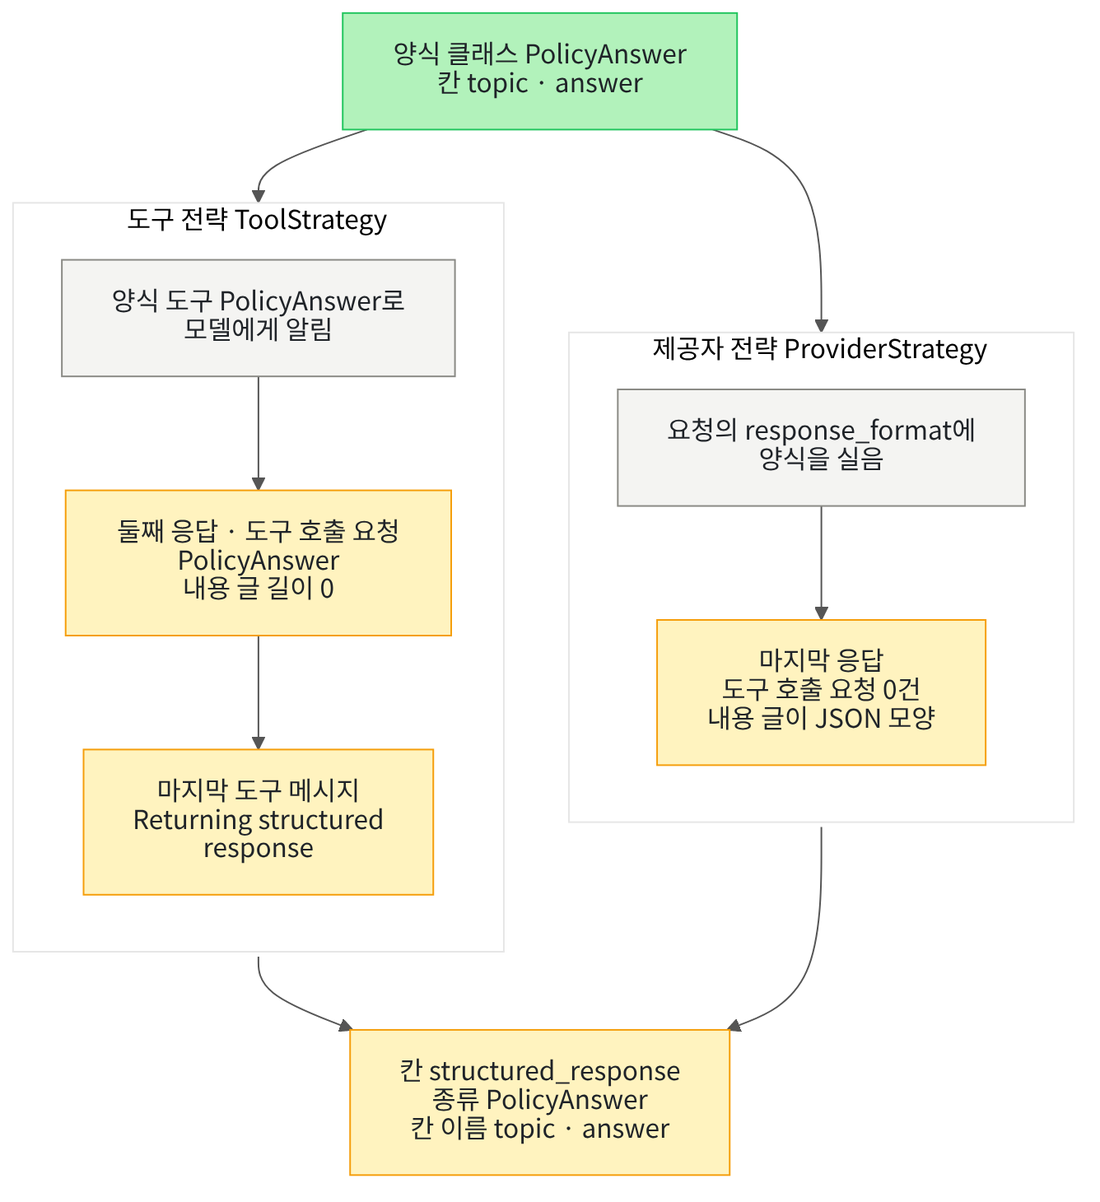

## 1. 준비

01절에서는 함수 `create_agent`로 모델과 도구를 오가는 에이전트 그래프를 만들었습니다.
그 그래프는 답을 모델이 쓴 글 한 덩어리로 내놓았습니다.
이 절에서는 같은 그래프가 답을 정해 둔 칸에 담아 내놓게 합니다.
Ch 6 03절에서 본 구조화 출력을 에이전트 그래프에 붙이는 일입니다.

첫 셀은 패키지 일곱 개를 설치하고 설치된 판 번호를 출력합니다.
도구 파일이 NumPy를 쓰므로, 01절처럼 numpy도 함께 설치합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "langgraph==1.2.11" "numpy==2.5.3" "pydantic==2.13.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("numpy:", version("numpy"))
print("pydantic:", version("pydantic"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langgraph: 1.2.11
numpy: 2.5.3
pydantic: 2.13.5


python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `langgraph: 1.2.11`·`numpy: 2.5.3`·`pydantic: 2.13.5`·`python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
양식 클래스를 적는 `BaseModel`·`Field`는 Ch 6 03절, `Literal`은 Ch 19 02절에서 썼습니다.
새 이름은 모듈 `langchain.agents.structured_output`에서 가져오는 두 전략입니다.

In [2]:
# 양식 클래스를 적을 이름과 두 전략을 가져오고, 01절에서 쓴 이름도 함께 가져옵니다
from typing import Literal

from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.structured_output import ProviderStrategy, ToolStrategy
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool

# 앞에서 배운 함수는 도구 파일에서 가져옵니다
from runner_tools import agent_row, estimate_cost, show_messages, sum_usage

print("이 절에서 새로 가져온 이름:", "ToolStrategy", "ProviderStrategy")

이 절에서 새로 가져온 이름: ToolStrategy ProviderStrategy


**결과 읽기** — 출력 줄 `이 절에서 새로 가져온 이름: ToolStrategy ProviderStrategy`가 보입니다.
모듈 `langchain.agents.structured_output`은 에이전트 그래프의 구조화 출력 설정을 모아 둔 곳입니다.

앞에서 배운 함수는 `runner_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

함수 `show_messages`는 Ch 19 06절, `sum_usage`는 Ch 19 05절에서 배웠습니다.
함수 `estimate_cost`는 Ch 6 06절에서 배웠습니다.
함수 `agent_row`는 01절 10절에서 처음 적은 함수입니다.
이 절부터 다시 쓰므로, 본문을 글자 그대로 도구 파일에 옮겼습니다.

## 2. 키와 모델 준비

모델은 01절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.
이렇게 만든 모델 객체를 이 절의 에이전트 그래프 셋에 모두 넘깁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 양식 칸에 쓰는 글이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 이 모델로 실행한 결과입니다.

## 3. 규정 자료와 도구

이 절도 01절의 자료실 규정과 도구를 그대로 씁니다.
다음 셀은 01절 3절 셀과 글자까지 같은 코드입니다.

In [5]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
변수 `topics`는 7절에서 양식 칸 값을 견줄 때 다시 씁니다.

다음 셀도 01절 3절의 도구 셀과 글자까지 같은 코드입니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(이 오류를 그래프 안에서 다루는 법은 Ch 20 02절에서 보았습니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 이름은 `lookup_policy`이고, 모델이 부르면 규정 글 하나를 내놓습니다.

## 4. 양식 클래스

구조화 출력은 Ch 6 03절에서 본 말로, 모델 답을 정해 둔 칸에 담아 받는 방법입니다.
Ch 6 03절에서는 모델 객체의 메서드 `with_structured_output`에 양식 클래스를 넘겼습니다.
양식 클래스는 칸마다 자료형과 규칙을 적어 값을 검사하는 클래스입니다.
이 절에서는 에이전트 그래프를 만들 때 인자 `response_format`에 양식을 넘깁니다.

다음 셀은 칸 둘을 가진 양식 클래스를 적습니다.
주제어 칸에는 Ch 19 02절의 `Literal`로 고를 수 있는 값 셋을 정해 둡니다.
함수 `Field`에 적은 설명 글은 모델에게 칸 뜻을 알려 주는 글로 요청에 실립니다.

In [7]:
# 답을 담을 양식 클래스를 적습니다(칸 둘: 주제어와 한 문장 답)
class PolicyAnswer(BaseModel):
    # 주제어 칸에는 괄호 안 세 값 가운데 하나만 적을 수 있습니다(Ch 19 02절 Literal)
    topic: Literal["대출", "운영", "연체"] = Field(description="답의 근거가 된 규정의 주제어")
    answer: str = Field(description="찾은 규정 글에 근거한 한 문장 답")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 이름은 `topic`과 `answer` 둘이고, 메서드 없이 칸만 적었습니다.
클래스 이름 뒤 괄호의 `BaseModel`은 Ch 6 03절처럼 값 검사 기능을 물려받은 양식이라는 뜻입니다.

다음 셀은 Ch 19 02절처럼 메서드 `model_json_schema`로 양식을 JSON 모양 설명으로 바꿔 봅니다.
라이브러리 문서는 이 양식을 원어로 schema라고 부르고, 이 절에서는 「양식」이라고 부릅니다.

In [8]:
# 양식 클래스를 JSON 모양 설명으로 바꿔, 꼭 채울 칸과 주제어 칸의 규칙을 봅니다(Ch 19 02절)
answer_form = PolicyAnswer.model_json_schema()
print("꼭 채울 칸:", answer_form["required"])
topic_form = answer_form["properties"]["topic"]
print("주제어 칸의 고를 수 있는 값:", topic_form["enum"])
print("주제어 칸의 설명:", topic_form["description"])

꼭 채울 칸: ['topic', 'answer']
주제어 칸의 고를 수 있는 값: ['대출', '운영', '연체']
주제어 칸의 설명: 답의 근거가 된 규정의 주제어


**결과 읽기** — 출력 줄 `꼭 채울 칸: ['topic', 'answer']`로, 두 칸 모두 꼭 채워야 합니다.
출력 줄 `주제어 칸의 고를 수 있는 값: ['대출', '운영', '연체']`는 `Literal`에 적은 값 셋입니다.
라벨 `주제어 칸의 설명:` 뒤 글은 함수 `Field`에 적은 설명 그대로입니다.
설치판 소스로 보면, 두 전략 모두 이 JSON 모양 설명을 요청에 싣고, 싣는 자리만 다릅니다.

## 5. 두 전략으로 붙이기

인자 `response_format`에 넘기는 값으로 구조화 출력의 방법을 고릅니다.
라이브러리 LangChain은 이 방법을 전략이라고 부르고, 두 가지를 줍니다.

도구 전략(`ToolStrategy`)은 양식을 도구 하나로 만들어 모델에게 알립니다.
모델이 그 도구를 부르면, 도구 호출 요청의 인자를 양식 값으로 받습니다.
이 절에서는 양식으로 만든 이 도구를 양식 도구라고 부릅니다.

제공자 전략(`ProviderStrategy`)은 모델 제공자(OpenAI)의 구조화 출력 기능을 씁니다.
요청에 양식을 실어 보내면, 응답의 내용 글이 양식 모양으로 옵니다.

다음 셀은 01절과 같은 에이전트 그래프에 도구 전략을 붙입니다.
시스템 메시지 글은 01절 4절과 같은 글입니다.

In [9]:
# 01절과 같은 에이전트 그래프에 양식을 도구 전략(ToolStrategy)으로 붙입니다(요청은 아직 보내지 않음)
system_text = "교육센터 자료실 안내 도우미입니다. 자료실 규정을 묻는 질문에는 lookup_policy 도구로 찾은 규정 글에 근거해 답하세요."
tool_format = ToolStrategy(PolicyAnswer)
tool_agent = create_agent(
    model,
    tools=[lookup_policy],
    system_prompt=system_text,
    response_format=tool_format,
)
print("만든 것의 종류:", type(tool_agent).__name__)

만든 것의 종류: CompiledStateGraph


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`로, 01절과 같은 종류의 그래프입니다.
이 줄에서도 모델 요청은 나가지 않습니다.

설치판 소스(`factory.py` 1423행)로 보면, 도구 전략은 도구를 꼭 하나 이상 부르게 요청합니다.
그래서 이 그래프에서는 마지막 응답도 글이 아니라 도구 호출 요청이 될 것입니다.

다음 셀은 같은 에이전트 그래프에 제공자 전략을 붙입니다.
바꾼 것은 인자 `response_format`의 값 하나입니다.

In [10]:
# 같은 에이전트 그래프에 양식을 제공자 전략(ProviderStrategy)으로 붙입니다(바꾼 것은 response_format 값 하나)
provider_format = ProviderStrategy(PolicyAnswer)
provider_agent = create_agent(
    model,
    tools=[lookup_policy],
    system_prompt=system_text,
    response_format=provider_format,
)
print("만든 것의 종류:", type(provider_agent).__name__)

만든 것의 종류: CompiledStateGraph


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`입니다.
두 그래프는 인자 `response_format`의 값만 다릅니다.

설치판 소스(`factory.py` 1391~1404행)로 보면, 제공자 전략은 양식을 요청의 `response_format` 칸에 싣습니다.
OpenAI 계열 모델이면 함께 싣는 도구 명세에 설정 `strict=True`를 붙입니다.
양식 쪽을 꼭 지키게 하는 설정은 `ProviderStrategy(…, strict=True)`이고, 이 절은 주지 않았습니다.
그래서 요청 글의 양식 쪽에는 `"strict": false`가 실립니다.
이것은 모델을 부르지 않고 요청 글만 만들어 본 확인이고, 이번 노트북에서는 출력하지 않았습니다.

## 6. 두 그래프의 모양

01절 5절에서는 설계 객체의 속성 `branches`로 조건 함수 이름과 갈 수 있는 곳을 보았습니다.
이번에는 그래프 둘을 보므로, 그 셀이 하던 일을 함수 하나로 묶습니다.

In [11]:
# 에이전트 그래프 하나의 조건 함수 이름과 갈 수 있는 곳을 출력합니다(01절 5절 반복을 함수로 묶음)
def print_branches(graph_agent):
    branches = graph_agent.builder.branches
    for source in branches:
        specs = branches[source]
        for name in specs:
            # 속성 ends는 이름표와 갈 곳을 이은 딕셔너리라, 값만 모으면 갈 수 있는 곳입니다
            ends = list(specs[name].ends.values())
            print(source, "| 조건 함수:", name, "| 갈 수 있는 곳:", ends)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_branches`는 에이전트 그래프 하나를 받아, 조건부 엣지마다 한 줄씩 출력합니다.
한 줄에는 조건부 엣지를 적은 노드, 조건 함수 이름, 갈 수 있는 곳이 들어갑니다.

다음 셀은 도구 전략 그래프의 노드와 조건 함수를 봅니다.

In [12]:
# 도구 전략을 붙인 그래프의 노드와 조건 함수를 봅니다
print("도구 전략 그래프의 노드:", list(tool_agent.builder.nodes))
print_branches(tool_agent)

도구 전략 그래프의 노드: ['model', 'tools']
tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model', '__end__']
model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__', 'model']


**결과 읽기** — 출력 줄 `도구 전략 그래프의 노드: ['model', 'tools']`로, 노드는 01절과 같습니다.
출력 줄 `tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model', '__end__']`에서 갈 곳이 둘입니다.
01절 그래프에서 이 조건 함수가 갈 수 있는 곳은 `model` 하나였습니다.
출력 줄 `model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__', 'model']`에도 `model`이 더해졌습니다.

01절 5절에서 소스로만 본 경우가 여기서 출력으로 보입니다.
소스 1678~1685행을 보면, 양식 도구가 있을 때 조건 함수 `tools_to_model`이 끝으로도 갈 수 있게 적힙니다.
소스 1702~1705행을 보면, 양식이 있을 때 모델 노드가 자기 자신으로 가는 갈래가 더해집니다.
소스로 보면 양식 검사에 실패해 모델에게 다시 요청할 때 쓰는 갈래이고, 이번에 실행하지 않았습니다.

다음 셀은 제공자 전략 그래프를 같은 함수로 봅니다.

In [13]:
# 제공자 전략을 붙인 그래프의 노드와 조건 함수를 봅니다
print("제공자 전략 그래프의 노드:", list(provider_agent.builder.nodes))
print_branches(provider_agent)

제공자 전략 그래프의 노드: ['model', 'tools']
tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model']
model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__', 'model']


**결과 읽기** — 출력 줄 `제공자 전략 그래프의 노드: ['model', 'tools']`로 노드는 같습니다.
출력 줄 `tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model']`은 01절 그래프와 같습니다.
제공자 전략에는 양식 도구가 없어, 도구 실행 노드 뒤는 늘 모델 노드로 돌아갑니다.
모델 노드 뒤 갈 곳 `['tools', '__end__', 'model']`은 도구 전략 그래프와 같습니다.

## 7. 도구 전략으로 질문 보내기

첫 질문은 01절 6절과 같은 대출 질문입니다.
실행 전에 예상해 봅니다.
모델이 먼저 `lookup_policy`로 규정을 찾고, 그다음 양식 도구를 부를 것입니다.
그러면 모델 요청은 2번이고, 메시지 칸에는 01절보다 메시지가 하나 더 붙을 것입니다.

In [14]:
# 01절과 같은 대출 질문을 도구 전략 그래프에 보냅니다(모델 노드를 지날 때마다 모델 요청 1번)
loan_question = "자료실에서 일반 도서를 며칠 빌릴 수 있나요?"
tool_state = {"messages": [HumanMessage(content=loan_question)]}
tool_result = tool_agent.invoke(tool_state)
tool_keys = list(tool_result.keys())
print("결과 딕셔너리의 키:", tool_keys)
print("메시지 칸의 메시지 수:", len(tool_result["messages"]))

결과 딕셔너리의 키: ['messages', 'structured_response']
메시지 칸의 메시지 수: 5


**결과 읽기** — 출력 줄 `결과 딕셔너리의 키: ['messages', 'structured_response']`입니다.
01절 결과의 키는 `messages` 하나였고, 이번에는 칸 `structured_response`가 더 나왔습니다.
출력 줄 `메시지 칸의 메시지 수: 5`로, 01절 대출 질문보다 하나 많습니다.

다음 셀은 01절처럼 도구 파일 함수 `show_messages`로 메시지 칸을 차례로 출력합니다.

In [15]:
# 메시지 칸을 차례로 출력합니다(Ch 19 06절 함수 show_messages)
print("메시지 칸:")
show_messages(tool_result["messages"])

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: ['PolicyAnswer']
ToolMessage | 결과 상태: success | 내용: Returning structured response: topic='대출' answer='일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.'


**결과 읽기** — 라벨 줄 `메시지 칸:` 아래 다섯 줄입니다.
둘째 줄 `AIMessage | 도구 호출 요청: ['lookup_policy']`와 셋째 줄 도구 메시지는 01절과 같은 모양입니다.
넷째 줄은 `AIMessage | 도구 호출 요청: ['PolicyAnswer']`로, 양식 클래스 이름이 도구 이름이 되었습니다.
다섯째 줄 도구 메시지는 내용이 `Returning structured response:`로 시작합니다.

설치판 소스(`factory.py` 1255~1276행)로 보면, 이 도구 메시지는 도구 실행 노드가 아니라 모델 노드가 만듭니다.
모델 노드는 양식 도구 요청의 인자를 양식 클래스로 검사해 칸 `structured_response`에 담습니다.
그리고 요청과 짝을 맞추려고 이 글을 도구 메시지로 붙입니다.
도구 메시지 내용의 뒤쪽 글은 모델이 채운 값이라 실행마다 달라질 수 있습니다.

다음 셀은 양식 값이 모델 응답의 어디에 담겨 왔는지 봅니다.

In [16]:
# 양식 값이 어디에 담겨 왔는지 봅니다(마지막 도구 메시지 바로 앞의 응답)
form_response = tool_result["messages"][-2]
print("그 응답의 내용 글 길이:", len(form_response.content))
form_call = form_response.tool_calls[0]
print("도구 이름:", form_call["name"], "| 인자:", form_call["args"])
last_tool_message = tool_result["messages"][-1]
print("마지막 도구 메시지의 이름:", last_tool_message.name)

그 응답의 내용 글 길이: 0
도구 이름: PolicyAnswer | 인자: {'topic': '대출', 'answer': '일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.'}
마지막 도구 메시지의 이름: PolicyAnswer


**결과 읽기** — 출력 줄 `그 응답의 내용 글 길이: 0`으로, 이 응답에는 글이 없었습니다.
양식 값은 도구 호출 요청의 인자에 담겨 왔고, 인자의 키는 양식 칸 이름 `topic`·`answer`와 같습니다.
출력 줄 `마지막 도구 메시지의 이름: PolicyAnswer`로, 마지막 도구 메시지가 양식 도구 요청의 짝입니다.

인자의 값은 모델이 채운 값이라 실행마다 달라질 수 있습니다.
이번 실행에서는 주제어 칸이 `대출`이고, 답 칸에는 도구 메시지의 규정 글이 그대로 들어 있었습니다.

이번 흐름을 끝으로 보낸 것은, 소스(`factory.py` 1953~1968행)로 보면 조건 함수 `model_to_tools`입니다.
양식 도구 요청은 도구 실행 노드로 보내지 않고, 칸 `structured_response`에 값이 생겼기 때문입니다.
소스 2028~2030행으로 보면, 양식 도구 쪽에서 `tools_to_model`이 끝으로 가는 것은 두 요청이 한 응답에 함께 올 때입니다.
이번에는 규정 요청과 양식 도구 요청이 다른 응답에 와서, 그 경우는 실행하지 않았습니다.

다음 셀은 칸 `structured_response`에 담긴 값을 봅니다.
메서드 `model_dump`는 Ch 6 03절에서 본, 양식 객체를 딕셔너리로 바꾸는 메서드입니다.

In [17]:
# 칸 structured_response에 담긴 값의 종류와 칸 이름을 봅니다
tool_answer = tool_result["structured_response"]
print("structured_response의 종류:", type(tool_answer).__name__)
tool_dump = tool_answer.model_dump()
tool_form_keys = list(tool_dump.keys())
print("칸 이름:", tool_form_keys)
print("주제어 칸 값이 정해 둔 셋 안인가:", tool_answer.topic in topics)
# 라이브러리가 양식 클래스로 검사해 만든 값이라, 종류는 실행마다 같아야 합니다
assert type(tool_answer).__name__ == "PolicyAnswer", "칸 structured_response에는 양식 클래스 객체가 담겨야 합니다"

structured_response의 종류: PolicyAnswer
칸 이름: ['topic', 'answer']
주제어 칸 값이 정해 둔 셋 안인가: True


**결과 읽기** — 출력 줄 `structured_response의 종류: PolicyAnswer`로, 칸에는 양식 클래스 객체가 담겼습니다.
출력 줄 `칸 이름: ['topic', 'answer']`는 4절에서 적은 칸 둘과 같습니다.
출력 줄 `주제어 칸 값이 정해 둔 셋 안인가: True`입니다.
양식 클래스가 값을 검사하므로, 셋 밖의 값이면 검사에 걸려 이 칸에 담기지 않습니다.
셀 끝 `assert`는 모델이 쓴 글이 아니라, 라이브러리가 만든 값의 종류에만 걸었습니다.

## 8. 제공자 전략으로 질문 보내기

같은 대출 질문을 제공자 전략 그래프에 보냅니다.
실행 전에 예상해 봅니다.
양식 도구가 없으므로, 규정을 찾은 뒤 마지막 응답이 양식 모양의 글로 올 것입니다.
그러면 모델 요청은 2번, 메시지는 01절과 같은 넷일 것입니다.

In [18]:
# 같은 대출 질문을 제공자 전략 그래프에 보냅니다
provider_state = {"messages": [HumanMessage(content=loan_question)]}
provider_result = provider_agent.invoke(provider_state)
provider_keys = list(provider_result.keys())
print("결과 딕셔너리의 키:", provider_keys)
print("메시지 칸의 메시지 수:", len(provider_result["messages"]))

결과 딕셔너리의 키: ['messages', 'structured_response']
메시지 칸의 메시지 수: 4


**결과 읽기** — 출력 줄 `결과 딕셔너리의 키: ['messages', 'structured_response']`는 도구 전략과 같습니다.
출력 줄 `메시지 칸의 메시지 수: 4`로, 도구 전략보다 하나 적고 01절 대출 질문과 같습니다.

다음 셀은 메시지 칸을 차례로 출력합니다.

In [19]:
# 메시지 칸을 차례로 출력합니다
print("메시지 칸:")
show_messages(provider_result["messages"])

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 `메시지 칸:` 아래 네 줄입니다.
둘째·셋째 줄은 도구 전략과 같은 `lookup_policy` 요청과 그 도구 메시지입니다.
마지막 줄은 `AIMessage | 도구 호출 요청: []`로, 양식 도구 요청이 없습니다.
메시지 칸에는 양식 도구 요청도, 그 짝 도구 메시지도 남지 않았습니다.

다음 셀은 양식 값이 이 마지막 응답의 어디에 담겨 왔는지 봅니다.

In [20]:
# 양식 값이 어디에 담겨 왔는지 봅니다(메시지 칸의 마지막 응답)
last_response = provider_result["messages"][-1]
print("마지막 응답의 도구 호출 요청 수:", len(last_response.tool_calls))
print("마지막 응답의 내용 글:")
print(last_response.content)

마지막 응답의 도구 호출 요청 수: 0
마지막 응답의 내용 글:
{"topic":"대출","answer":"일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다."}


**결과 읽기** — 출력 줄 `마지막 응답의 도구 호출 요청 수: 0`입니다.
라벨 줄 `마지막 응답의 내용 글:` 아래가 모델이 쓴 글이고, 중괄호로 싼 JSON 모양입니다.
이 글의 키가 양식 칸 이름 `topic`·`answer`입니다.

설치판 소스(`factory.py` 1204~1219행)로 보면, 모델 노드는 요청이 없는 응답의 글을 양식 클래스로 읽습니다.
그 결과를 칸 `structured_response`에 담고, 메시지는 더하지 않습니다.
글 안의 값은 실행마다 달라질 수 있습니다.
이번 실행에서는 7절 도구 전략의 인자와 같은 값이었습니다.

다음 셀은 칸 `structured_response`에 담긴 값을 봅니다.

In [21]:
# 칸 structured_response에 담긴 값의 종류와 칸 이름을 봅니다
provider_answer = provider_result["structured_response"]
print("structured_response의 종류:", type(provider_answer).__name__)
provider_dump = provider_answer.model_dump()
provider_form_keys = list(provider_dump.keys())
print("칸 이름:", provider_form_keys)
print("주제어 칸 값이 정해 둔 셋 안인가:", provider_answer.topic in topics)
# 도구 전략과 같은 양식 클래스로 검사해 만든 값이라, 종류는 실행마다 같아야 합니다
assert type(provider_answer).__name__ == "PolicyAnswer", "칸 structured_response에는 양식 클래스 객체가 담겨야 합니다"

structured_response의 종류: PolicyAnswer
칸 이름: ['topic', 'answer']
주제어 칸 값이 정해 둔 셋 안인가: True


**결과 읽기** — 출력 줄 `structured_response의 종류: PolicyAnswer`로, 도구 전략과 같은 종류가 담겼습니다.
출력 줄 `칸 이름: ['topic', 'answer']`와 `주제어 칸 값이 정해 둔 셋 안인가: True`도 같습니다.
두 전략은 메시지 칸의 모양이 달랐지만, 칸 `structured_response`에 담긴 값의 종류와 칸은 같았습니다.

## 9. 두 전략 견주기

다음 셀은 01절 10절 함수 `agent_row`로 두 결과를 한 줄씩 적습니다.
함수의 첫 칸 이름은 `질문`이지만, 여기서는 전략 이름을 넣습니다.

In [22]:
# 두 전략의 기록을 한 줄씩 적어 출력합니다(01절 10절 함수 agent_row — 도구 파일로 옮김)
strategy_rows = []
strategy_rows.append(agent_row("ToolStrategy", tool_result))
strategy_rows.append(agent_row("ProviderStrategy", provider_result))
print("전략 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝")
for row in strategy_rows:
    print(row["질문"], "|", row["모델 요청 수"], "|", row["도구 메시지 수"], "|", row["호출 ID 짝"])
    # 도구 메시지마다 요청 id를 옮겨 적는 것은 코드가 하는 일이라, 짝은 매번 맞아야 합니다
    assert row["호출 ID 짝"], "도구 메시지마다 같은 차례의 요청 id가 옮겨져야 합니다"

전략 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝
ToolStrategy | 2 | 2 | True
ProviderStrategy | 2 | 1 | True


**결과 읽기** — 라벨 줄 아래 두 줄입니다.
도구 전략은 `ToolStrategy | 2 | 2 | True`이고, 제공자 전략은 `ProviderStrategy | 2 | 1 | True`입니다.
모델 요청은 둘 다 2번이고, 도구 메시지 수만 하나 차이 납니다.
그 하나는 도구 전략의 모델 노드가 양식 도구 요청에 붙인 도구 메시지입니다.
그래서 도구 메시지 수로 모델 요청 수를 짐작하지 않고, 01절처럼 응답 수로 셉니다.

호출 ID 짝은 두 전략 모두 맞았고, 셀의 `assert`로 확인했습니다.
양식 도구 요청의 id도 라이브러리가 만든 도구 메시지에 그대로 옮겨졌습니다.

## 10. 사용량과 예상 비용

다음 셀은 Ch 19 05절 함수 `sum_usage`로 두 결과의 요청 수와 토큰을 더합니다.
함수가 세는 요청 수는 01절처럼 메시지 칸의 응답 수입니다.

In [23]:
# 두 결과의 요청 수와 입력·출력 토큰을 더합니다(Ch 19 05절 함수 sum_usage)
tool_usage = sum_usage(tool_result["messages"])
provider_usage = sum_usage(provider_result["messages"])
print("도구 전략 사용량:", tool_usage)
print("제공자 전략 사용량:", provider_usage)

도구 전략 사용량: {'requests': 2, 'input_tokens': 572, 'output_tokens': 60}
제공자 전략 사용량: {'requests': 2, 'input_tokens': 768, 'output_tokens': 55}


**결과 읽기** — 두 사용량 모두 `'requests': 2`로, 모델 요청은 2번씩이었습니다.
입력 토큰은 도구 전략 `'input_tokens': 572`, 제공자 전략 `'input_tokens': 768`입니다.
01절 대출 질문의 입력 토큰은 456이었고, 두 전략 모두 그보다 많습니다.
소스로 보면 도구 전략은 양식을 도구 명세로, 제공자 전략은 `response_format` 칸으로 싣습니다.
입력 토큰 차이가 어느 몫에서 왔는지는 이번에 나눠 세지 않았습니다.

출력 토큰은 모델이 쓴 글에 따라 실행마다 달라질 수 있습니다.
이번 실행에서는 도구 전략 `'output_tokens': 60`, 제공자 전략 `'output_tokens': 55`였습니다.

다음 셀은 Ch 6 06절 함수 `estimate_cost`로 두 사용량의 예상 비용을 셉니다.
요금은 2026-09-17 요금표의 100만 토큰당 달러입니다.

In [24]:
# 2026-09-17 요금표(100만 토큰당 달러)로 두 결과의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
tool_cost = round(estimate_cost(tool_usage, input_rate, cached_input_rate, output_rate), 6)
provider_cost = round(estimate_cost(provider_usage, input_rate, cached_input_rate, output_rate), 6)
print("도구 전략 예상 비용(달러):", tool_cost)
print("제공자 전략 예상 비용(달러):", provider_cost)

도구 전략 예상 비용(달러): 0.000699
제공자 전략 예상 비용(달러): 0.000824


**결과 읽기** — 라벨 `도구 전략 예상 비용(달러):`와 `제공자 전략 예상 비용(달러):` 뒤 값이 예상 비용입니다.
요금표로 어림한 값이고, 청구 금액이 아닙니다.
사용량에 캐시 입력 칸이 없어, 입력 토큰은 모두 입력 요금으로 셌습니다.

출력 토큰이 실행마다 달라질 수 있어, 이 값도 달라질 수 있습니다.
이번 실행에서는 도구 전략 `0.000699`달러, 제공자 전략 `0.000824`달러였습니다.
이 한 번의 값으로 어느 전략이 싸다고 말하지 않습니다.

## 11. 값 바꿔 보기 · 양식 클래스를 그대로 넘기기

바꿀 값은 인자 `response_format` 하나입니다.
전략으로 감싸지 않고, 양식 클래스 `PolicyAnswer`를 그대로 넘깁니다.
설치판 소스(`factory.py` 1357~1367행)로 보면, 이때는 요청할 때 모델의 기능 표를 보고 전략을 고릅니다.
기능 표는 모델 객체의 속성 `profile`에 담긴 딕셔너리입니다.

다음 셀은 그 기능 표에서 구조화 출력을 지원한다는 표시를 봅니다.

In [25]:
# 모델 객체의 기능 표에서 구조화 출력을 지원한다는 표시를 봅니다(라이브러리가 전략을 고를 때 읽는 값)
model_profile = model.profile
print("기능 표의 structured_output:", model_profile["structured_output"])

기능 표의 structured_output: True


**결과 읽기** — 출력 줄 `기능 표의 structured_output: True`입니다.
소스(`factory.py` 583~596행)로 보면, 이 값이 참이면 제공자 전략을 고릅니다.
참이 아니면 정해 둔 모델 이름 목록(174~194행)과 한 번 더 견주고, 거기에도 없으면 도구 전략을 고릅니다.
이 절의 모델 이름도 그 목록에 들어 있습니다.

실행 전에 예상해 봅니다.
이 모델은 표시가 참이므로, 메시지 칸이 8절 제공자 전략과 같은 모양일 것입니다.
다음 셀은 양식 클래스를 그대로 넘겨 그래프를 만들고, 먼저 모양을 봅니다.

In [26]:
# 바꿀 값: 인자 response_format에 전략으로 감싸지 않은 양식 클래스를 그대로 넘깁니다
auto_agent = create_agent(
    model,
    tools=[lookup_policy],
    system_prompt=system_text,
    response_format=PolicyAnswer,
)
print("양식 클래스를 그대로 넘긴 그래프의 노드:", list(auto_agent.builder.nodes))
print_branches(auto_agent)

양식 클래스를 그대로 넘긴 그래프의 노드: ['model', 'tools']
tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model', '__end__']
model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__', 'model']


**결과 읽기** — 출력 줄 `tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model', '__end__']`입니다.
도구 실행 노드 뒤 갈 곳이 도구 전략 그래프와 같습니다.
소스 1024~1036행을 보면, 양식 클래스만 받은 그래프는 만들 때 양식 도구를 먼저 준비해 둡니다.
어느 전략으로 요청할지는 모델 노드가 요청을 보낼 때 정합니다.

다음 셀에서 같은 대출 질문을 보내 실제 메시지 칸을 봅니다.

In [27]:
# 같은 대출 질문을 보내고 메시지 칸을 차례로 출력합니다
auto_state = {"messages": [HumanMessage(content=loan_question)]}
auto_result = auto_agent.invoke(auto_state)
print("메시지 칸:")
show_messages(auto_result["messages"])

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 `메시지 칸:` 아래 네 줄입니다.
마지막 줄이 `AIMessage | 도구 호출 요청: []`이고, 양식 도구 요청과 그 짝 도구 메시지가 없습니다.
그래프 모양은 도구 전략과 같았지만, 메시지 칸은 8절 제공자 전략과 같은 모양입니다.
소스와 이 출력으로 보면, 모델 노드는 기능 표를 보고 제공자 전략으로 요청했습니다.

다음 셀은 바꾼 값의 기록을 9절 표에 더해 세 줄로 봅니다.

In [28]:
# 바꾼 값의 기록을 더해 세 줄을 출력하고, 칸 structured_response에 담긴 값의 종류를 봅니다
strategy_rows.append(agent_row("양식 클래스 그대로", auto_result))
print("전략 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝")
for row in strategy_rows:
    print(row["질문"], "|", row["모델 요청 수"], "|", row["도구 메시지 수"], "|", row["호출 ID 짝"])
auto_answer = auto_result["structured_response"]
print("양식 클래스 그대로 | structured_response의 종류:", type(auto_answer).__name__)

전략 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝
ToolStrategy | 2 | 2 | True
ProviderStrategy | 2 | 1 | True
양식 클래스 그대로 | 2 | 1 | True
양식 클래스 그대로 | structured_response의 종류: PolicyAnswer


**결과 읽기** — 라벨 줄 아래 셋째 줄이 `양식 클래스 그대로 | 2 | 1 | True`입니다.
둘째 줄 제공자 전략과 같은 수입니다.
마지막 줄로 담긴 값의 종류도 `PolicyAnswer`로 같습니다.
이 결과는 기능 표가 구조화 출력을 참으로 적은 이 모델의 경우입니다.
기능 표와 이름 목록 어디에도 없는 모델에서는 도구 전략이 골라지고, 그 경우는 이번에 실행하지 않았습니다.

## 정리

1. 인자 `response_format`에 양식을 넘기면, 결과에 칸 `structured_response`가 생기고 양식 객체가 담겼습니다.
2. 도구 전략은 양식 도구 요청과 그 짝 도구 메시지를 남겨, 대출 질문의 메시지가 다섯이었습니다.
3. 제공자 전략과 양식 클래스를 그대로 넘긴 실행은 메시지가 넷이었고, 모델 요청은 세 실행 모두 2번이었습니다.

03절에서는 상태에 칸을 하나 더하는 법과, 실행할 때 상태 밖으로 넘기는 값을 봅니다.